# Nonlinear Feature Regression - Case Study

In this case case, we will work with the 


You are working with a civil-engineering laboratory that studies **concrete compressive strength**. Preparing and destructively testing concrete specimens is costly and time-consuming, so the laboratory would like to predict compressive strength from the composition of the concrete mixture and its curing age. To this end, you are given a dataset collecting the results of several concrete strength tests.  The dataset is public available at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength).

- I-Cheng Yeh, *Concrete Compressive Strength*, UCI Machine Learning Repository.
- DOI: https://doi.org/10.24432/C5PK67
- License: Creative Commons Attribution 4.0 International (CC BY 4.0).

According to the authors of the dataset 
> Concrete is the most important material in civil engineering. The concrete compressive strength is a highly nonlinear function of age and ingredients.

In this notebook, we will build a regression model to predict the compressive strength of a concrete mixture from its base ingredients. Specifically, we will discuss how nonlinear features can be crafted, and the limitations of this hand-made approach.

In [3]:
%pip install numpy pandas matplotlib seaborn openpyxl
%pip install ipywidgets
%pip install python-calamine

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
RANDOM_STATE = 101

%matplotlib inline


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 936.3/936.3 kB 25.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


# Import and inspect the dataset

In [4]:
data = pd.read_excel('Concrete_Data.xls')
data.head()

,Cement [kg/m^3],Blast Furnace Slag [kg/m^3],Fly Ash [kg/m^3],Water [kg/m^3],Superplasticizer [kg/m^3],Coarse Aggregate [kg/m^3],Fine Aggregate [kg/m^3],Age [day],Concrete compressive strength [Mpa]
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Cement [kg/m^3]                       1030 non-null   float64
 1   Blast Furnace Slag [kg/m^3]           1030 non-null   float64
 2   Fly Ash [kg/m^3]                      1030 non-null   float64
 3   Water [kg/m^3]                        1030 non-null   float64
 4   Superplasticizer [kg/m^3]             1030 non-null   float64
 5   Coarse Aggregate [kg/m^3]             1030 non-null   float64
 6   Fine Aggregate [kg/m^3]               1030 non-null   float64
 7   Age [day]                             1030 non-null   int64  
 8   Concrete compressive strength [Mpa]   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [6]:
data.describe()

,Cement [kg/m^3],Blast Furnace Slag [kg/m^3],Fly Ash [kg/m^3],Water [kg/m^3],Superplasticizer [kg/m^3],Coarse Aggregate [kg/m^3],Fine Aggregate [kg/m^3],Age [day],Concrete compressive strength [Mpa]
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


# Dealing with duplicate data

In the dataset, there are some duplicate observations. Duplicates can arise from data-entry mistakes, concatenating the same file twice, or database joins.

An **exact duplicate** means that **every input** and the **measured target** are identical in two or more rows. Why can this be dangerous?

Suppose an exact copy of one observation is placed in the training set while another copy is placed in the test set. The test observation is then not genuinely unseen. The model has already been trained on the same point, which can make generalization performance look better than it really is.

### TO DO: remove the duplicate entries

In [7]:
# Rename the columns
RAW_FEATURES = ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']
COLUMNS_NAMES = RAW_FEATURES + ['Strength']
data.columns = COLUMNS_NAMES

In [8]:
print('Number of duplicated row:', data.duplicated().sum()) 

# Show examples of duplicate
all_doubles = data.duplicated(keep = False)
data.loc[all_doubles].sort_values(COLUMNS_NAMES).head()

Number of duplicated row: 25


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171


In [9]:
data_clean = data.drop_duplicates().reset_index(drop=True)

print('Rows before removing duplicates:', len(data))
print('Rows after removing duplicates:', len(data_clean))

Rows before removing duplicates: 1030
Rows after removing duplicates: 1005


# Exploratory data analysis

### TO DO: plot the distribution of the data, its correlation, and identify some nonlinear behavior

array([[<Axes: title={'center': 'Cement'}>,
        <Axes: title={'center': 'Slag'}>,
        <Axes: title={'center': 'FlyAsh'}>],
       [<Axes: title={'center': 'Water'}>,
        <Axes: title={'center': 'Superplasticizer'}>,
        <Axes: title={'center': 'CoarseAggregate'}>],
       [<Axes: title={'center': 'FineAggregate'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Strength'}>]], dtype=object)

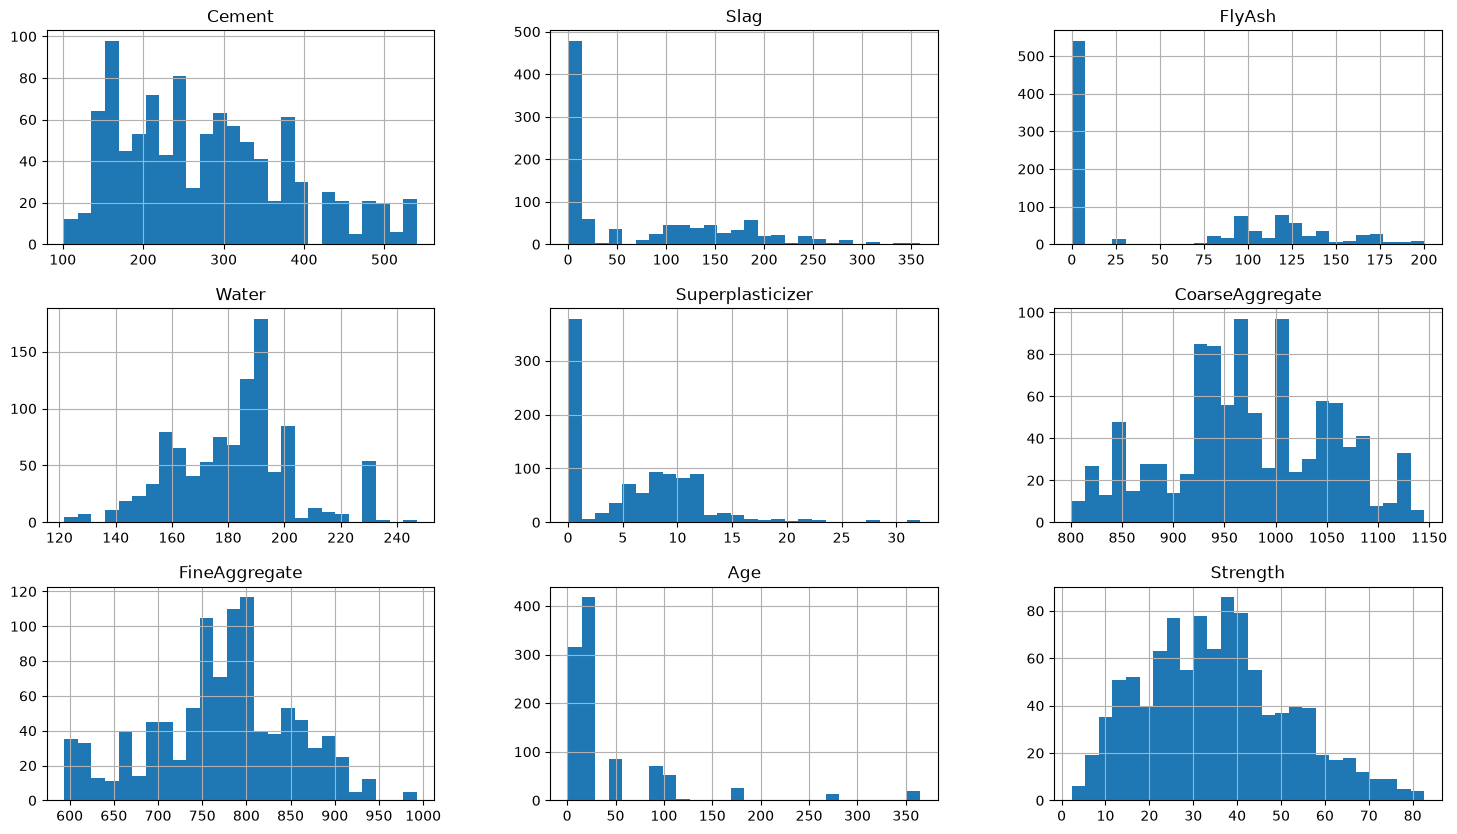

In [10]:
data_clean.hist(figsize=(18,10), bins=26)

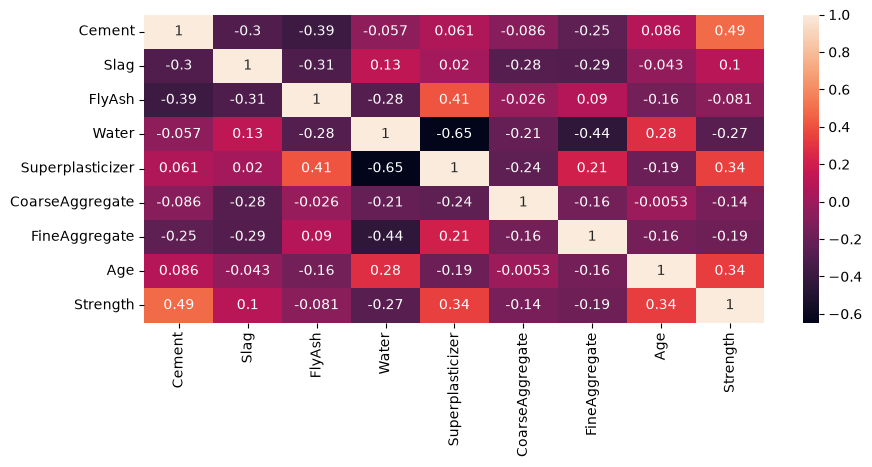

In [11]:
# Compute correlation
correlation_matrix = data_clean.corr(method='pearson')

# Visualize
plt.figure(figsize=(10,4))
sns.heatmap(correlation_matrix, annot=True)
plt.show()

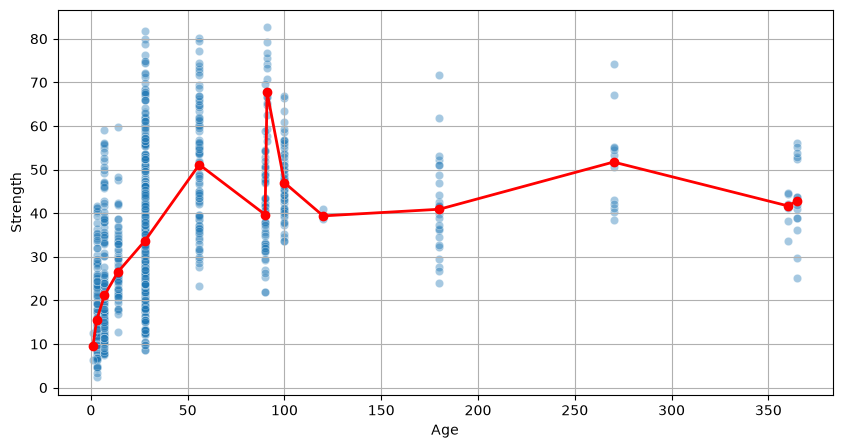

In [12]:
age_mean = data_clean.groupby('Age')['Strength'].median().reset_index()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data_clean, x='Age', y='Strength', alpha=0.4)
plt.plot(age_mean['Age'], age_mean['Strength'], marker='o', linewidth=2, color='red')

plt.xlabel('Age')
plt.ylabel('Strength')
plt.grid()
plt.show()

# Building a regression model

Let's start by splitting our data into validation and training datasets

### TO DO: Fit and evaluate a linear regression model $ y = \theta_0 + \theta_1 x_1 + \ldots + \theta_n x_n $

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Separate the data
X = data_clean[RAW_FEATURES].copy()
y = data_clean['Strength'].copy()

# Split into training and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

# Fit model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test)

# Evaluate performance using RMSE
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, linear_predictions)))

RMSE: 10.54339376967505


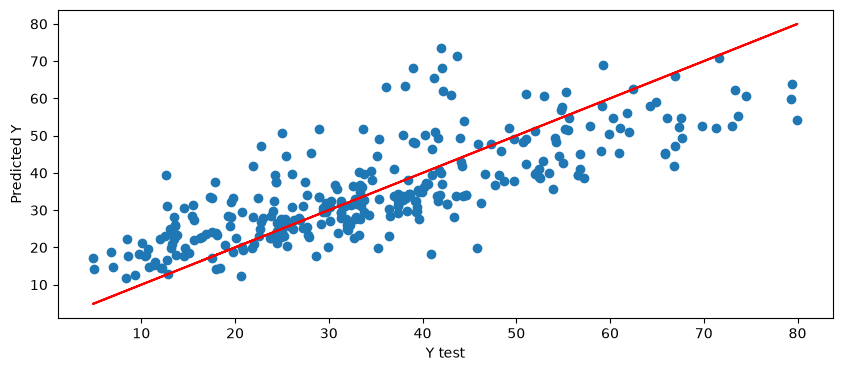

In [14]:
plt.figure(figsize=(10,4))
plt.scatter(y_test, linear_predictions)
plt.xlabel('Y test')
plt.ylabel('Predicted Y')
plt.plot(y_test, y_test, color = 'red')

plt.show()


# 7. A linear model with nonlinear features

From the exploratory data analysis, we noticed that the relationship between `Age` and `Strength` wasn't linear. How can we embed this information into the regression?

Consider as an example a one-dimensional nonlinear model

$$
y = \theta_0 + \theta_1 x + \theta_2 x^2 + \theta_3 \log(1+x),
$$

where the unknown (tuning parameters) are the coefficients $\theta_0, \theta_1, \theta_2, \theta_3$. Although the model is nonlinear, we can rewrite it as 

$$
y = \underbrace{\begin{bmatrix}
    \theta_0 & \theta_1 & \theta_2 & \theta_3
\end{bmatrix}}_{\Theta} \underbrace{\begin{bmatrix}
    1 \\ x \\ x^2 \\ \log(1+x)
\end{bmatrix}}_{\phi(x)} = \Theta \ \phi(x).
$$

Thus, the model is still linear in $\Theta$, and we can estimate its optimal parameters by training a linear regression model. We just need to correctly define the regressor $\phi(x)$.

### TO DO: Generate a nonlinear regressor and re-train the linear model
Use the additional features

$$
\begin{aligned}
    \text{WaterBinderRatio} & = \frac{\text{Water}}{\text{Cement} + \text{Slag} + \text{FlyAsh}} \\[4mm]
    \text{LogAge} & = \log(1 + \text{Age}) \\[2mm]
    \text{BinderLogAge} & = (\text{Cement} + \text{Slag} + \text{FlyAsh}) \cdot \log(1 + \text{Age})
\end{aligned}
$$


In [15]:
def add_features(X_raw):
    X = X_raw.copy()

    # Compute nonlinear functions
    binder = X['Cement'] + X['Slag'] + X['FlyAsh']
    X['WaterBinderRatio'] = X['Water'] / binder
    X['LogAge'] = np.log1p(X['Age'])
    X['BinderLogAge'] = binder * X['LogAge']

    return X

In [16]:
X_train_manual = add_features(X_train)
X_test_manual = add_features(X_test)

In [17]:
# Train new model
linear_manual = LinearRegression()
linear_manual.fit(X_train_manual, y_train)

# Generate predictions
nonlinear_predictions = linear_manual.predict(X_test_manual)

# Evaluate
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, nonlinear_predictions)))

RMSE: 6.93579865731902


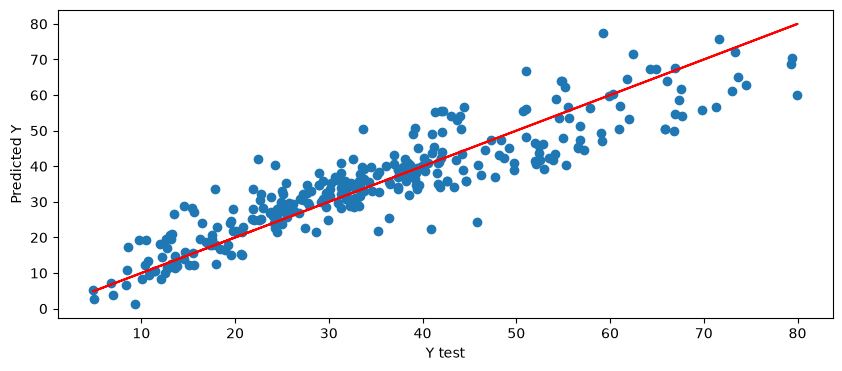

In [18]:
plt.figure(figsize=(10,4))
plt.scatter(y_test, nonlinear_predictions)
plt.xlabel('Y test')
plt.ylabel('Predicted Y')
plt.plot(y_test, y_test, color = 'red')

plt.show()


# Overfitting and feature selection

We improved our metric! Why shouldn't we insert additional nonlinear function? We can only improve the accuracy, right? 

Wrong, if we increase too much the complexity of our model we incur in overfitting. To show this, we now consider polynomial features. 

Polynomials are universal function approximations, so if they are taken with sufficiently high order, we can approximate **ANY** function! An example of second-order polynomials with two features is

$$
y = \begin{bmatrix}
    \theta_0 & \theta_1 & \theta_2 & \theta_3 & \theta_4 & \theta_5
\end{bmatrix} \begin{bmatrix}
    1 \\ x_1 \\ x_2 \\ x_1 x_2 \\ x_1^2 \\ x_2^2
\end{bmatrix}
$$



In [ ]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Store the fitted models so that we can reuse them later without rebuilding everything.
polynomial_models = {}
polynomial_results = []

for degree in range(1, 6):
    # Pipeline ensures that polynomial generation and scaling are learned from training data only.
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scale', StandardScaler()),
        ('linear', LinearRegression())
    ])

    # Fit the complete pipeline on the training set.
    model.fit(X_train, y_train)

    # Predictions on training and validation data.
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Number of generated polynomial terms can be read from the fitted transformer.
    n_features_generated = model.named_steps['poly'].n_output_features_

    polynomial_results.append({
        'Degree': degree,
        'Number of features': n_features_generated,
        'Training RMSE': np.sqrt(metrics.mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(metrics.mean_squared_error(y_test, test_pred)),
        'Train prediction': train_pred,
        'Test prediction': test_pred
    })

    polynomial_models[degree] = model

polynomial_results = pd.DataFrame(polynomial_results)
polynomial_results
# increasing too much the dof, may be ovefitted so high training error

,Degree,Number of features,Training RMSE,Test RMSE,Train prediction,Test prediction
0,1,8,10.183052,10.543394,"[33.487588, 22.046949, 26.273511, 31.244878, 3...","[21.012241, 19.718362, 54.606224, 28.070185, 2..."
1,2,44,7.291179,7.350935,"[25.999021, 18.906775, 28.610128, 30.269444, 4...","[17.229099, 16.323487, 53.365675, 23.904185, 1..."
2,3,164,4.310279,6.090671,"[24.283054, 27.518598, 26.860708, 29.500598, 4...","[16.908175, 10.665148, 56.90524, 19.758273, 13..."
3,4,494,2.137187,16.505438,"[17.709985, 24.780646, 23.891934, 26.977041, 4...","[16.875431, 12.780643, 55.415374, 18.298259, 1..."
4,5,1286,1.427972,51.488470,"[19.933969, 23.464373, 23.875928, 25.500097, 3...","[21.607725, 11.306293, 23.567071, 25.323097, 2..."


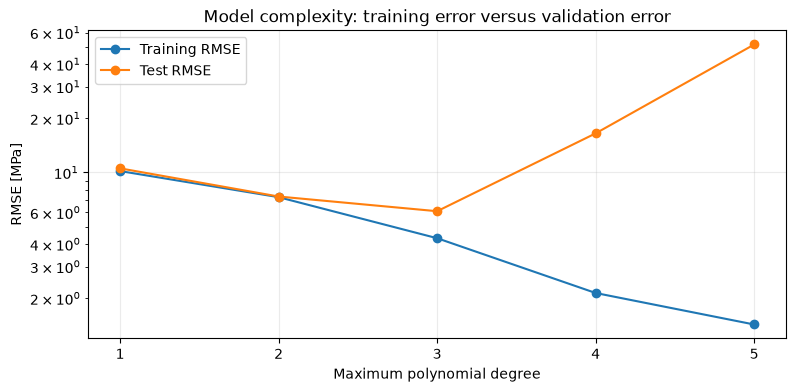

In [20]:
# Plot training and validation RMSE as model complexity increases.
plt.figure(figsize=(9, 4))
plt.plot(
    polynomial_results['Degree'],
    polynomial_results['Training RMSE'],
    marker='o',
    label='Training RMSE'
)
plt.plot(
    polynomial_results['Degree'],
    polynomial_results['Test RMSE'],
    marker='o',
    label='Test RMSE'
)
plt.xlabel('Maximum polynomial degree')
plt.ylabel('RMSE [MPa]')
plt.title('Model complexity: training error versus validation error')
plt.xticks(polynomial_results['Degree'])
plt.legend()
plt.yscale('log')
plt.grid(alpha=0.25)
plt.show()

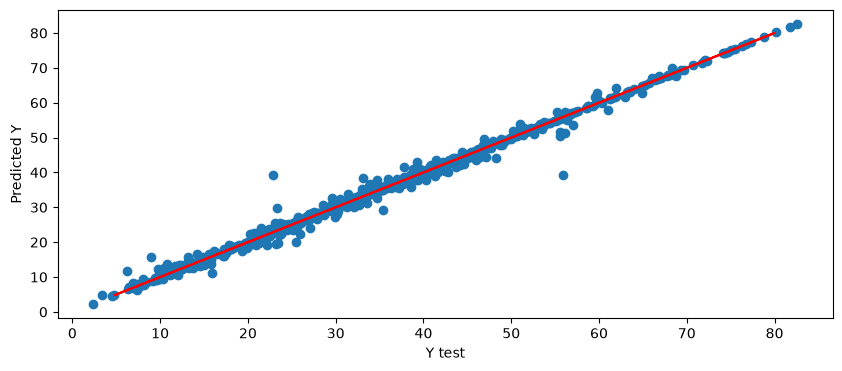

In [21]:
plt.figure(figsize=(10,4))
plt.scatter(y_train, polynomial_results.loc[4, 'Train prediction'])
plt.xlabel('Y test')
plt.ylabel('Predicted Y')
plt.plot(y_test, y_test, color = 'red')

plt.show()

# How can we address this issue? 
- Don't select a model that is too complex for our task. For example, with a 5-degree polynomial our model has around 1200 parameters with only 1000 samples in our dataset!
- Select only relevant features! Probably most of the high-order polynomial features are not relevant... but we cannot know a priori if a feature is relevant or not.
- Introduce regularization to constraint the optimized coefficient. An example is LASSO, which forces the optimization to select only "few" parameters different from zero 

$$
\min_\Theta \quad \sum_i \Big \lVert y_i - \Theta \phi(x_i) \Big \rVert_2^2 + \lambda \lVert \Theta \rVert_1
$$ 

$\quad \;\;\;$ However, regularization helps with overfitting, but cannot produce good nonlinear features from raw data!

Can we learn directly from data what is a "good" feature instead of manually selecting it?